# NLP — Carnet 06 : la recherche d'information depuis zéro (TF-IDF, BM25)
**Navigation** : [<< Précédent — 05. HMM et décodage de Viterbi](05-HMM-Viterbi.ipynb) | [Index de la série](README.md) | **06 (ce notebook)**

La série a modélisé la probabilité d'un texte : la probabilité d'un mot et d'un n-gramme
(carnet 02), d'une séquence d'étiquettes (03), d'un arbre (04), d'une chaîne d'états cachés (05).
Ce carnet **inverse la question**. Au lieu de demander *« quelle est la probabilité de ce
texte ? »*, on demande *« **quel document est le plus pertinent pour cette requête ?** »*.

C'est la question de la **recherche d'information** (retrieval) : un corpus de documents, une
requête, et l'obligation de **classer** les documents par pertinence. La machine qui y répond
est la même que celle du carnet 02 — des fréquences de termes, pondérées par leur **rareté** —
et elle se programme en Python stdlib + numpy, sans aucun réseau de neurones.

On implémente **depuis zéro** trois classifieurs, du naïf au canonique :

1. le **classement brut par fréquence** (bag-of-words) — et le défaut qui le ruine ;
2. le **TF-IDF** — pondération par rareté, qui fait tomber à zéro le terme omniprésent ;
3. le **BM25** de Robertson — la fonction de classement standard, avec saturation du terme
   (`k1`) et normalisation de longueur (`b`).

Et on **mesure** la qualité de classement (`Recall@3`) sur trois requêtes portant chacune un
ensemble de documents pertinents étiqueté. Le résultat est **calculé dans une sortie**, pas
raconté.


In [1]:
import math
import numpy as np

print("imports ok — math (stdlib) + numpy")

imports ok — math (stdlib) + numpy


## 1. Le corpus, et le terme qui va tout décider

Un corpus minuscule, **auto-contenu** (aucune donnée externe) : 8 documents courts sur quatre
thèmes (recherche, compression, jeux, langue). Chaque document est une liste de termes.

Un détail fait toute la leçon du carnet : le terme **`note`** est présent dans **les 8
documents**. Il est donc *omniprésent* — exactement ce que l'on veut, car c'est lui qui va
séparer le classifieur naïf des deux autres.


In [2]:
# Corpus embarque, auto-contenu (8 documents, 4 themes) — aucun donne externe.
# Le terme "note" est omniprésent (8/8 docs) : il sera le discriminant du carnet.
corpus = {
    "doc1": ["recherche", "documents", "pertinence", "classement", "note"],
    "doc2": ["recherche", "recherche", "index", "inversion", "note"],
    "doc3": ["recherche", "note"],
    "doc4": ["compression", "entropie", "huffman", "code", "note"],
    "doc5": ["compression", "compression", "entropie", "shannon", "note", "long"],
    "doc6": ["jeux", "strategie", "equilibre", "note", "note", "note"],
    "doc7": ["langue", "mots", "modeles", "probabilistes", "note"],
    "doc8": ["langue", "mots", "mots", "modeles", "n-grammes", "probabilistes", "note", "long"],
}

N = len(corpus)
vocab = sorted({t for toks in corpus.values() for t in toks})
print(f"corpus : {N} documents, vocabulaire de {len(vocab)} termes")
print("longueurs : " + ", ".join(f"{d}={len(t)}" for d, t in sorted(corpus.items())))
print(f"le terme 'note' est présent dans "
      f"{sum(1 for t in corpus.values() if 'note' in t)}/{N} documents")

corpus : 8 documents, vocabulaire de 21 termes
longueurs : doc1=5, doc2=5, doc3=2, doc4=5, doc5=6, doc6=6, doc7=5, doc8=8
le terme 'note' est présent dans 8/8 documents


In [3]:
# Fréquence documentaire df(t) : dans combien de documents le terme t apparaît au moins une fois.
df = {t: sum(1 for toks in corpus.values() if t in toks) for t in vocab}
print("df par terme (combien de documents le contiennent) :")
for t in vocab:
    print(f"  {t:<14} df={df[t]}")

df par terme (combien de documents le contiennent) :
  classement     df=1
  code           df=1
  compression    df=2
  documents      df=1
  entropie       df=2
  equilibre      df=1
  huffman        df=1
  index          df=1
  inversion      df=1
  jeux           df=1
  langue         df=2
  long           df=2
  modeles        df=2
  mots           df=2
  n-grammes      df=1
  note           df=8
  pertinence     df=1
  probabilistes  df=2
  recherche      df=3
  shannon        df=1
  strategie      df=1


## 2. Le classement brut — et le défaut qui le ruine

Le classifieur le plus naïf note un document en **additionnant les comptages bruts** des termes
de la requête : plus un document contient de fois les mots de la requête, plus il est «
pertinent ». C'est le **bag-of-words**.

Son défaut est immédiat : il ne distingue pas un terme **diagnostique** (rare, donc
caractéristique d'un sujet) d'un terme **omniprésent** (présent partout, donc sans
information). Répéter trois fois un mot que *tout le monde* dit ne rend pas un document plus
pertinent.


In [4]:
# Baseline naive : score d'un document = somme des comptages bruts des termes de la requete.
def raw_tf_score(doc, query):
    toks = corpus[doc]
    return sum(toks.count(q) for q in query)

def rank_by(scores):
    # Tri deterministe : score decroissant, puis nom de document croissant (determinisme des ex aequo).
    return [d for d, _ in sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))]

In [5]:
# TF-IDF : ponderer chaque terme par sa RARETE.
#   idf(t) = log(N / df(t))
# Le terme present dans TOUS les documents a idf = log(N/N) = 0 : il ne compte plus.
def idf(t):
    return math.log(N / df[t])

def tfidf_vector(doc):
    toks = corpus[doc]
    return {t: toks.count(t) * idf(t) for t in vocab}

def tfidf_cosine(query, doc):
    # Similarite de cosinus entre la requete (presence binaire x idf) et le document (tf x idf).
    qv = {t: idf(t) for t in query if t in vocab}
    dv = tfidf_vector(doc)
    dot = sum(qv[t] * dv[t] for t in qv)
    nq  = math.sqrt(sum(w * w for w in qv.values()))
    nd  = math.sqrt(sum(w * w for w in dv.values()))
    return dot / (nq * nd) if nq and nd else 0.0

## 3. Le BM25 — le classifieur canonique

Le **BM25** (Robertson) est la fonction de classement que l'on retrouve derrière la plupart des
moteurs de recherche texte. Par terme de la requête, elle ajoute :

$$\mathrm{score}(d) \;+=\; \mathrm{idf}(t) \;\cdot\; \frac{f(t,d)\,(k_1+1)}{f(t,d) \;+\; k_1\left(1 - b + b\,\dfrac{|d|}{\overline{dl}}\right)}$$

avec deux **réglages** qui font tout l'intérêt du classifieur :

- **`k1` (saturation du terme)** : la contribution d'un terme croît de façon *sous-linéaire*
  avec sa fréquence `f(t,d)` — mentionner un mot dix fois ne rapporte pas dix fois plus qu'une ;
- **`b` (normalisation de longueur)** : via `|d|/d̄`, un **court** document qui mentionne le
  terme est jugé plus pertinent qu'un **long** document qui le mentionne une fois au passage.

Le `idf` est le même que celui du TF-IDF : c'est lui qui, ici, réduit le terme omniprésent à
néant.


In [6]:
# BM25 (Robertson) — le classifieur standard de la recherche d'information textuelle.
K1, B = 1.5, 0.75
avgdl = sum(len(t) for t in corpus.values()) / N

def bm25_score(doc, query):
    toks = corpus[doc]
    L = len(toks)
    s = 0.0
    for q in query:
        f = toks.count(q)
        if f == 0:
            continue
        s += idf(q) * (f * (K1 + 1)) / (f + K1 * (1 - B + B * L / avgdl))
    return s

print(f"longueur moyenne du corpus avgdl = {avgdl:.3f}  (K1={K1}, B={B})")

longueur moyenne du corpus avgdl = 5.250  (K1=1.5, B=0.75)


## 4. Classer, puis **mesurer** la qualité

Trois requêtes, chacune avec un **ensemble de documents pertinents** que l'on connaît (c'est le
*gold*). La requête 1 contient le terme omniprésent `note` — c'est elle qui va départager les
classifieurs. On classe avec les trois, puis on mesure le **`Recall@3`** : la fraction des
documents pertinents qu'un classifieur sait ramener dans son top-3.


In [7]:
queries = {
    "Q1  recherche+note": (["recherche", "note"],         {"doc1", "doc2", "doc3"}),
    "Q2  compression":    (["compression", "entropie"],   {"doc4", "doc5"}),
    "Q3  modeles":        (["modeles", "probabilistes"], {"doc7", "doc8"}),
}

def topk(scores, k=3):
    return rank_by(scores)[:k]

rankers = {
    "TF brut": lambda q: {d: raw_tf_score(d, q) for d in corpus},
    "TF-IDF":  lambda q: {d: tfidf_cosine(q, d) for d in corpus},
    "BM25":    lambda q: {d: bm25_score(d, q) for d in corpus},
}

print("classement par requete (top-3) — l'asteroque marque un document pertinent :\n")
for name, (q, rel) in queries.items():
    print(f"{name}   (pertinents : {sorted(rel)})")
    for rname, fn in rankers.items():
        top = topk(fn(q))
        marks = "  ".join(f"{d}{'*' if d in rel else ''}" for d in top)
        print(f"   {rname:<8} -> {marks}")
    print()

classement par requete (top-3) — l'asteroque marque un document pertinent :

Q1  recherche+note   (pertinents : ['doc1', 'doc2', 'doc3'])
   TF brut  -> doc2*  doc6  doc1*
   TF-IDF   -> doc3*  doc2*  doc1*
   BM25     -> doc2*  doc3*  doc1*

Q2  compression   (pertinents : ['doc4', 'doc5'])
   TF brut  -> doc5*  doc4*  doc1
   TF-IDF   -> doc5*  doc4*  doc1
   BM25     -> doc5*  doc4*  doc1

Q3  modeles   (pertinents : ['doc7', 'doc8'])
   TF brut  -> doc7*  doc8*  doc1
   TF-IDF   -> doc7*  doc8*  doc1
   BM25     -> doc7*  doc8*  doc1



In [8]:
def recall_at_k(ranked, relevant, k=3):
    return len(set(ranked[:k]) & relevant) / len(relevant)

hdr = f"{'classifieur':<10}" + "".join(f"{q:>16}" for q in queries) + f"{'moyenne':>12}"
print(hdr)
print("-" * len(hdr))
for rname, fn in rankers.items():
    cells = [recall_at_k(topk(fn(q)), rel) for q, rel in queries.values()]
    line = f"{rname:<10}" + "".join(f"{c:16.3f}" for c in cells)
    print(line + f"{sum(cells) / len(cells):12.3f}")

classifieurQ1  recherche+note Q2  compression     Q3  modeles     moyenne
-------------------------------------------------------------------------
TF brut              0.667           1.000           1.000       0.889
TF-IDF               1.000           1.000           1.000       1.000
BM25                 1.000           1.000           1.000       1.000


In [9]:
# Le detail par terme du score BM25 sur Q1 : "recherche" porte tout le score, "note" vaut 0.
q = ["recherche", "note"]
print("décomposition du score BM25 par terme (Q1 = ['recherche','note']) :\n")
for doc in ("doc1", "doc2", "doc3", "doc6"):
    toks = corpus[doc]
    L = len(toks)
    parts = []
    for t in q:
        f = toks.count(t)
        if f:
            contrib = idf(t) * (f * (K1 + 1)) / (f + K1 * (1 - B + B * L / avgdl))
        else:
            contrib = 0.0
        parts.append(f"{t}={contrib:.3f}")
    print(f"  {doc} (len={L}): " + "  ".join(parts))

décomposition du score BM25 par terme (Q1 = ['recherche','note']) :

  doc1 (len=5): recherche=1.002  note=0.000
  doc2 (len=5): recherche=1.423  note=0.000
  doc3 (len=2): recherche=1.360  note=0.000
  doc6 (len=6): recherche=0.000  note=0.000


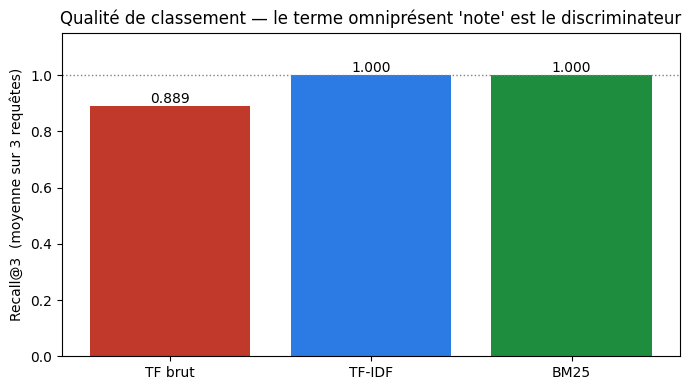

In [10]:
import matplotlib.pyplot as plt

names = list(rankers)
means = [sum(recall_at_k(topk(fn(q)), rel) for q, rel in queries.values()) / len(queries)
         for fn in rankers.values()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(names, means, color=["#c0392b", "#2c7be5", "#1e8e3e"])
ax.axhline(1.0, color="grey", ls=":", lw=1)
for i, m in enumerate(means):
    ax.text(i, m + 0.01, f"{m:.3f}", ha="center")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Recall@3  (moyenne sur 3 requêtes)")
ax.set_title("Qualité de classement — le terme omniprésent 'note' est le discriminateur")
fig.tight_layout()
plt.show()

### Interprétation

Le terme `note`, présent dans les 8 documents, est le seul point de départage du corpus. Le
**classement brut** n'y voit que du bruit : sur la requête 1, il compte trois fois `note` dans
`doc6` (le document de jeux) et le **promote en 2ᵉ position**, devant un document réellement
pertinent — son `Recall@3` tombe à **2/3**.

Le **TF-IDF** et le **BM25** y voient la solution : `idf(note) = log(8/8) = 0`, donc le terme
omniprésent **ne contribue plus à rien** (la décomposition ci-dessus le montre : `note=0.000`
partout, `recherche` porte seul le score). Les deux classifieurs atteignent **`Recall@3 = 3/3`
sur les trois requêtes**.

Sur un corpus aussi minuscule, TF-IDF et BM25 sont **à parité** — c'est mesuré, pas affirmé.
La valeur ajoutée du BM25 (saturation `k1`, normalisation de longueur `b`) ne se voit pas dans
le `Recall` ici, mais dans la **forme des scores** : c'est elle qui fait du BM25 le défaut de
production à l'échelle, là où le TF-IDF-cosinus reste un excellent pédagogique. Le fil rouge du
carnet tient en une phrase : **pondérer un terme par sa rareté, c'est exactement ce qui sépare
un moteur de recherche d'un compteur de mots.**


### Exercice 1 — l'idf

Réimplémentez `idf(t)` à partir du tableau `df` et du nombre de documents `N`, avec
`idf(t) = log(N / df(t))`. Vérifiez que `idf("note") == 0.0` et que `idf("pertinence") > 0`.


In [11]:
# Exercice 1 — à compléter :
def mon_idf(t):
    # TODO étudiant : idf(t) = log(N / df(t))
    print("Exercice à compléter : idf")
    return None

### Exercice 2 — un terme du BM25

Écrivez la **contribution d'un seul terme** `t` au score BM25 d'un document `d` :

$$\mathrm{idf}(t) \cdot \frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\left(1 - b + b\,|d|/\overline{dl}\right)}$$

Vérifiez que, pour `t = "note"`, la contribution est `0.0` sur **tout** document.


In [12]:
# Exercice 2 — à compléter :
def bm25_term(t, doc):
    # TODO étudiant : contribution d'un terme t au score BM25 de doc
    print("Exercice à compléter : contribution d'un terme BM25")
    return None

### Exercice 3 — le Recall@k

Écrivez `recall_at_k(ranked, relevant, k)` : la fraction des documents de `relevant` qui
apparaissent parmi les `k` premiers de la liste ordonnée `ranked`. Vérifiez que, pour la
requête 1 et le classement brut, elle rend `2/3`.


In [13]:
# Exercice 3 — à compléter :
def mon_recall(ranked, relevant, k=3):
    # TODO étudiant : fraction des relevant parmi les k premiers de ranked
    print("Exercice à compléter : recall@k")
    return None

## Conclusion

La recherche d'information n'est pas un tour de passe-passe : c'est la **même arithmétique de
fréquences** que le carnet 02, tournée vers l'utilisateur. Le bag-of-words classe en comptant ;
le TF-IDF et le BM25 classent en **pondérant chaque terme par sa rareté** — et c'est cette
pondération qui, mesurée sur un corpus minuscule, suffit à faire chuter un terme omniprésent à
zéro et à ramener les documents pertinents en tête. Le `Recall@3` calculé (2/3 pour le
comptage brut, 3/3 pour les deux classifieurs pondérés) est la preuve, en chiffres, que la
rareté est l'information. Le carnet prolonge la série NLP sur son principe : l'objet est
**calculé et vérifié**, pas seulement décrit.
